# Bloque B2 · Pronóstico de demanda del SEIN (protocolo v2)
Este cuaderno **reemplaza al bloque 1** para el artículo. Corrige el protocolo: la validación se hace a medianoche (igual que la prueba), el entrenamiento usa orígenes a medianoche (`PASO=24`, alineados con la tarea) y todos los modelos comparten partición.

Incluye: Ridge, LightGBM, ablación factorial 2×2×2 de la GRU (A salida directa vs. Ridge+corrección · B calendario básico vs. extendido · C pérdida L1 normalizada vs. L1 en MW), mezcla de modelos calibrada en un bloque aparte, y métricas de pico y rampas.

**Uso:** GPU T4 → ejecutar todo. Si se corta, vuelve a ejecutar todo: cada época guarda un checkpoint en Drive, lo terminado se omite y, si subes `EPOCAS`, continúa desde lo aprendido (no parte de cero). Todo se guarda en `results_v2/` dentro de la carpeta del proyecto en Drive.

In [1]:
from pathlib import Path
import subprocess, sys, os, importlib.util
try:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ_ = Path("/content/drive/MyDrive/MIA07 REDES NEURONALES Y APRENDIZAJE PROFUNDO")
    PROYECTO = next((c for c in (RAIZ_ / "23 PROYECTO FINAL" / "02_Repositorio_Codigo", RAIZ_ / "23 PROYECTO FINAL" / "04 PROYECTO COES DEMANDA",
                                 RAIZ_ / "24 PREVIOS PROYECTO FINAL" / "04 PROYECTO COES DEMANDA") if (c / "src" / "exp_v2.py").is_file()),
                    RAIZ_ / "23 PROYECTO FINAL" / "02_Repositorio_Codigo")
except ImportError:
    PROYECTO = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
assert (PROYECTO / "src" / "exp_v2.py").is_file(), f"Ajusta PROYECTO: {PROYECTO}"
for pkg, imp in (("holidays", "holidays"), ("lightgbm", "lightgbm")):
    if importlib.util.find_spec(imp) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
import torch
print("Proyecto:", PROYECTO)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no hay GPU (usa CPU: será más lento)")
assert (PROYECTO / "data" / "coes_demanda_limpio.csv").is_file(), "Falta data/coes_demanda_limpio.csv (ejecuta coes_descarga.py)"

Mounted at /content/drive
Proyecto: /content/drive/MyDrive/MIA07 REDES NEURONALES Y APRENDIZAJE PROFUNDO/23 PROYECTO FINAL/04 PROYECTO COES DEMANDA
GPU: Tesla T4


In [2]:
MODO = "completo"       # "rapido" = prueba de humo
SEMILLAS = [17, 42, 73] if MODO == "completo" else [17]
PASO = 24               # orígenes a medianoche (alineados con la tarea). Para la ablación de alineación usa 6 con otro nombre.
EPOCAS, PACIENCIA = (40, 6) if MODO == "completo" else (3, 2)    # sube EPOCAS para seguir desde lo aprendido
SALIDA = "results_v2" if MODO == "completo" else "results_v2_rapido"
HILOS = 2

def ejecutar(*extra, paso=None):
    cmd = [sys.executable, "-u", "src/exp_v2.py", "--resultados", SALIDA, "--hilos", str(HILOS), "--paso", str(paso or PASO), *extra]
    p = subprocess.Popen(cmd, cwd=PROYECTO, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for linea in p.stdout:
        if "Warning" not in linea and "eval_set" not in linea:
            print(linea, end="")
    if p.wait() != 0:
        raise RuntimeError("falló: " + " ".join(extra))
    os.sync()

gru = ["--semillas", *map(str, SEMILLAS), "--epocas", str(EPOCAS), "--paciencia", str(PACIENCIA)]

## 1. Referencias clásicas (rápidas): Ridge y LightGBM, con calendario básico (B0) y extendido (B1)

In [3]:
for B in (0, 1):
    ejecutar("--modo", "ridge", "--B", str(B))
    ejecutar("--modo", "lgbm", "--B", str(B))

==> ridge_B0 semilla 0: MAE test 99.9 MW | val_sel 96.5 | val_cal 85.0 | MAPE 1.42% | pico 117 MW / 2.33 h | rampa 49.9 | 4.8s
  warnings.warn(
  warnings.warn(
  warnings.warn(
==> lgbm_B0 semilla 0: MAE test 93.9 MW | val_sel 83.9 | val_cal 85.3 | MAPE 1.35% | pico 97 MW / 2.23 h | rampa 56.2 | 11.8s
==> ridge_B1 semilla 0: MAE test 100.1 MW | val_sel 93.9 | val_cal 85.3 | MAPE 1.42% | pico 118 MW / 2.42 h | rampa 50.4 | 6.1s
  warnings.warn(
  warnings.warn(
  warnings.warn(
==> lgbm_B1 semilla 0: MAE test 89.4 MW | val_sel 83.1 | val_cal 80.1 | MAPE 1.28% | pico 91 MW / 2.18 h | rampa 54.6 | 13.8s


## 2. Ablación factorial de la GRU (8 celdas × semillas)
`A1` = Ridge + corrección GRU (el Ridge base de cada origen de entrenamiento se ajusta solo con datos anteriores a su bloque de 2 años). Orden: primero las celdas más informativas (000, 100, 110, 111), luego el resto.

In [4]:
orden = [(0,0,0), (1,0,0), (1,1,0), (1,1,1), (0,1,0), (0,0,1), (1,0,1), (0,1,1)]
for a, b, c in orden:
    print()
    print(f"===== GRU A{a} B{b} C{c} =====")
    ejecutar("--modo", "gru", "--A", str(a), "--B", str(b), "--C", str(c), *gru)



===== GRU A0 B0 C0 =====
  ep1 train 0.5197 val_sel 1150.6 MW  1.5s
  ep2 train 0.1375 val_sel 383.7 MW  1.6s
  ep3 train 0.0963 val_sel 245.5 MW  1.7s
  ep4 train 0.0837 val_sel 198.3 MW  1.8s
  ep5 train 0.0769 val_sel 228.9 MW  1.9s
  ep6 train 0.0722 val_sel 194.3 MW  2.0s
  ep7 train 0.0676 val_sel 179.2 MW  2.1s
  ep8 train 0.0650 val_sel 189.8 MW  2.2s
  ep9 train 0.0629 val_sel 183.9 MW  2.3s
  ep10 train 0.0608 val_sel 188.7 MW  2.4s
  ep11 train 0.0583 val_sel 173.9 MW  2.5s
  ep12 train 0.0566 val_sel 184.7 MW  2.6s
  ep13 train 0.0572 val_sel 211.1 MW  2.7s
  ep14 train 0.0544 val_sel 167.1 MW  2.8s
  ep15 train 0.0525 val_sel 174.5 MW  2.9s
  ep16 train 0.0527 val_sel 199.1 MW  2.9s
  ep17 train 0.0516 val_sel 212.9 MW  3.0s
  ep18 train 0.0518 val_sel 154.5 MW  3.1s
  ep19 train 0.0488 val_sel 173.5 MW  3.2s
  ep20 train 0.0483 val_sel 173.6 MW  3.3s
  ep21 train 0.0484 val_sel 169.7 MW  3.4s
  ep22 train 0.0497 val_sel 154.3 MW  3.5s
  ep23 train 0.0486 val_sel 188.3 MW

## 2b. Otras arquitecturas con la mejor receta (Ridge + corrección, calendario extendido)
En el bloque 1 el **Transformer residual** (97,5 ± 1,5 MW) y la **CNN residual** (102,1 ± 2,3 MW) fueron las mejores redes. Aquí se prueban con la receta de B2 (A1 B1 C0) para ver si la mejora se suma.

In [5]:
for arq in ("cnn", "transformer"):
    print()
    print(f"===== {arq} A1 B1 C0 =====")
    ejecutar("--modo", "gru", "--arq", arq, "--A", "1", "--B", "1", "--C", "0", *gru)


===== cnn A1 B1 C0 =====
  ep1 train 0.0155 val_sel 91.3 MW  1.4s
  ep2 train 0.0150 val_sel 91.4 MW  1.6s
  ep3 train 0.0148 val_sel 90.7 MW  1.8s
  ep4 train 0.0147 val_sel 88.4 MW  1.9s
  ep5 train 0.0145 val_sel 92.1 MW  2.1s
  ep6 train 0.0145 val_sel 88.7 MW  2.3s
  ep7 train 0.0145 val_sel 88.3 MW  2.5s
  ep8 train 0.0145 val_sel 89.1 MW  2.7s
  ep9 train 0.0144 val_sel 88.3 MW  2.8s
  ep10 train 0.0143 val_sel 88.8 MW  3.0s
  ep11 train 0.0143 val_sel 88.6 MW  3.2s
  ep12 train 0.0143 val_sel 89.0 MW  3.4s
  ep13 train 0.0142 val_sel 88.4 MW  3.5s
  ep14 train 0.0141 val_sel 88.4 MW  3.7s
  ep15 train 0.0142 val_sel 88.2 MW  3.9s
  ep16 train 0.0141 val_sel 88.4 MW  4.1s
  ep17 train 0.0141 val_sel 88.5 MW  4.3s
  ep18 train 0.0140 val_sel 88.1 MW  4.5s
  ep19 train 0.0140 val_sel 89.2 MW  4.6s
  ep20 train 0.0140 val_sel 87.2 MW  4.8s
  ep21 train 0.0140 val_sel 86.9 MW  5.0s
  ep22 train 0.0139 val_sel 86.9 MW  5.2s
  ep23 train 0.0140 val_sel 85.0 MW  5.3s
  ep24 train 0.01

## 2c. Ablación: alineación de los orígenes de entrenamiento
`PASO=24` entrena solo con orígenes a medianoche (igual que la tarea). Con `6` y `3` hay más ventanas pero de otras horas del día. Se compara con el mismo Ridge y la misma GRU.

In [6]:
for p in (6, 3):
    ejecutar("--modo", "ridge", "--B", "1", "--nombre", f"ridge_B1_paso{p}", paso=p)
    ejecutar("--modo", "gru", "--A", "1", "--B", "1", "--C", "0", "--nombre", f"gru_A1B1C0_paso{p}", *gru, paso=p)

==> ridge_B1_paso6 semilla 0: MAE test 109.7 MW | val_sel 101.6 | val_cal 92.7 | MAPE 1.56% | pico 119 MW / 2.29 h | rampa 51.1 | 143.0s
  ep1 train 0.0163 val_sel 99.0 MW  0.8s
  ep2 train 0.0159 val_sel 97.1 MW  1.1s
  ep3 train 0.0157 val_sel 97.4 MW  1.4s
  ep4 train 0.0156 val_sel 96.5 MW  1.7s
  ep5 train 0.0156 val_sel 98.1 MW  2.0s
  ep6 train 0.0155 val_sel 94.1 MW  2.3s
  ep7 train 0.0155 val_sel 94.7 MW  2.6s
  ep8 train 0.0154 val_sel 97.2 MW  2.9s
  ep9 train 0.0153 val_sel 94.1 MW  3.2s
  ep10 train 0.0152 val_sel 95.1 MW  3.5s
  ep11 train 0.0152 val_sel 95.6 MW  3.9s
  ep12 train 0.0152 val_sel 94.3 MW  4.2s
==> gru_A1B1C0_paso6 semilla 17: MAE test 100.2 MW | val_sel 94.1 | val_cal 84.4 | MAPE 1.43% | pico 106 MW / 2.17 h | rampa 51.0 | 288.6s
  ep1 train 0.0162 val_sel 95.8 MW  0.4s
  ep2 train 0.0158 val_sel 95.2 MW  0.7s
  ep3 train 0.0156 val_sel 96.1 MW  1.0s
  ep4 train 0.0156 val_sel 96.9 MW  1.3s
  ep5 train 0.0155 val_sel 96.5 MW  1.6s
  ep6 train 0.0155 val_s

## 3. Resultados: tabla, efectos factoriales, mezcla calibrada, comparaciones pareadas y figuras

,modelo,tipo,n,mae,rmse,mape,pico_mw_mae,pico_hora_mae,rampa_mae,mae_laboral,mae_domingo,mae_feriado,mae_std,mae_vs,mae_vc,seg_train
0,lgbm_B1,modelo,1,89.36,120.49,1.28,90.77,2.18,54.56,84.44,94.49,171.22,NaN,83.15,80.08,13.80
1,transformer_A1B1C0,modelo,3,90.04,122.13,1.28,105.35,2.19,51.22,86.96,97.82,132.93,1.78,86.17,78.44,32.60
2,cnn_A1B1C0,modelo,3,92.45,125.38,1.31,109.46,2.28,51.29,89.07,101.14,138.22,2.00,86.32,78.81,12.10
3,gru_A1B1C1,modelo,3,92.95,126.67,1.32,108.36,2.25,51.25,89.37,102.34,137.88,0.45,87.60,79.72,10.67
4,gru_A1B1C0,modelo,3,93.21,126.84,1.33,108.42,2.24,51.16,89.27,104.02,140.86,0.30,87.84,79.74,10.90
5,lgbm_B0,modelo,1,93.90,129.03,1.35,96.53,2.23,56.21,88.88,95.66,197.79,NaN,83.91,85.29,11.80
6,gru_A1B0C1,modelo,3,94.01,131.19,1.34,108.97,2.22,50.75,89.65,101.93,170.58,0.55,91.23,80.63,8.37
7,gru_A1B0C0,modelo,3,94.27,131.56,1.35,108.58,2.22,50.72,89.38,102.49,177.64,0.33,91.61,80.29,7.00
8,gru_A1B1C0_paso3,modelo,3,96.32,130.26,1.37,103.60,2.24,52.01,95.36,95.60,143.11,0.48,89.88,86.35,548.67
9,gru_A1B1C0_paso6,modelo,3,99.43,135.28,1.42,106.53,2.18,51.07,96.97,103.27,154.79,3.19,92.68,83.94,278.17


efectos_factoriales.csv


,factor,efecto_medio_mw,desv_entre_semillas,lectura
0,A,-91.10,3.15,negativo = el nivel 1 reduce el MAE
1,B,4.30,9.54,negativo = el nivel 1 reduce el MAE
2,C,-0.54,3.17,negativo = el nivel 1 reduce el MAE


mezcla.csv


,esquema,pesos,mae_vc,mae_test
0,ridge_B1,1.0,85.25,100.14
1,transformer_A1B1C0,1.0,75.95,87.78
2,lgbm_B1,1.0,80.08,89.36
3,promedio simple,"[0.333, 0.333, 0.333]",74.53,84.40
4,pesos calibrados en val_cal,"[0.0, 0.6, 0.4]",72.26,81.27


comparaciones_v2.csv


,modelo,contra,dif_mae,ic95_bajo,ic95_alto,lectura
0,ridge_B1,coes_diaria,-4.00,-8.47,0.93,negativo = el modelo es mejor
1,ridge_B1,ridge_B0,0.25,-1.37,1.61,negativo = el modelo es mejor
2,transformer_A1B1C0,coes_diaria,-16.36,-19.96,-12.48,negativo = el modelo es mejor
3,transformer_A1B1C0,ridge_B0,-12.11,-15.09,-9.20,negativo = el modelo es mejor
4,lgbm_B1,coes_diaria,-14.79,-18.42,-10.88,negativo = el modelo es mejor
5,lgbm_B1,ridge_B0,-10.54,-13.96,-7.09,negativo = el modelo es mejor
6,mezcla_calibrada,coes_diaria,-22.87,-26.46,-18.85,negativo = el modelo es mejor
7,mezcla_calibrada,ridge_B0,-18.62,-21.71,-15.50,negativo = el modelo es mejor
8,cnn_A1B1C0,coes_diaria,-13.33,-17.11,-9.20,negativo = el modelo es mejor
9,cnn_A1B1C0,ridge_B0,-9.08,-11.79,-6.45,negativo = el modelo es mejor


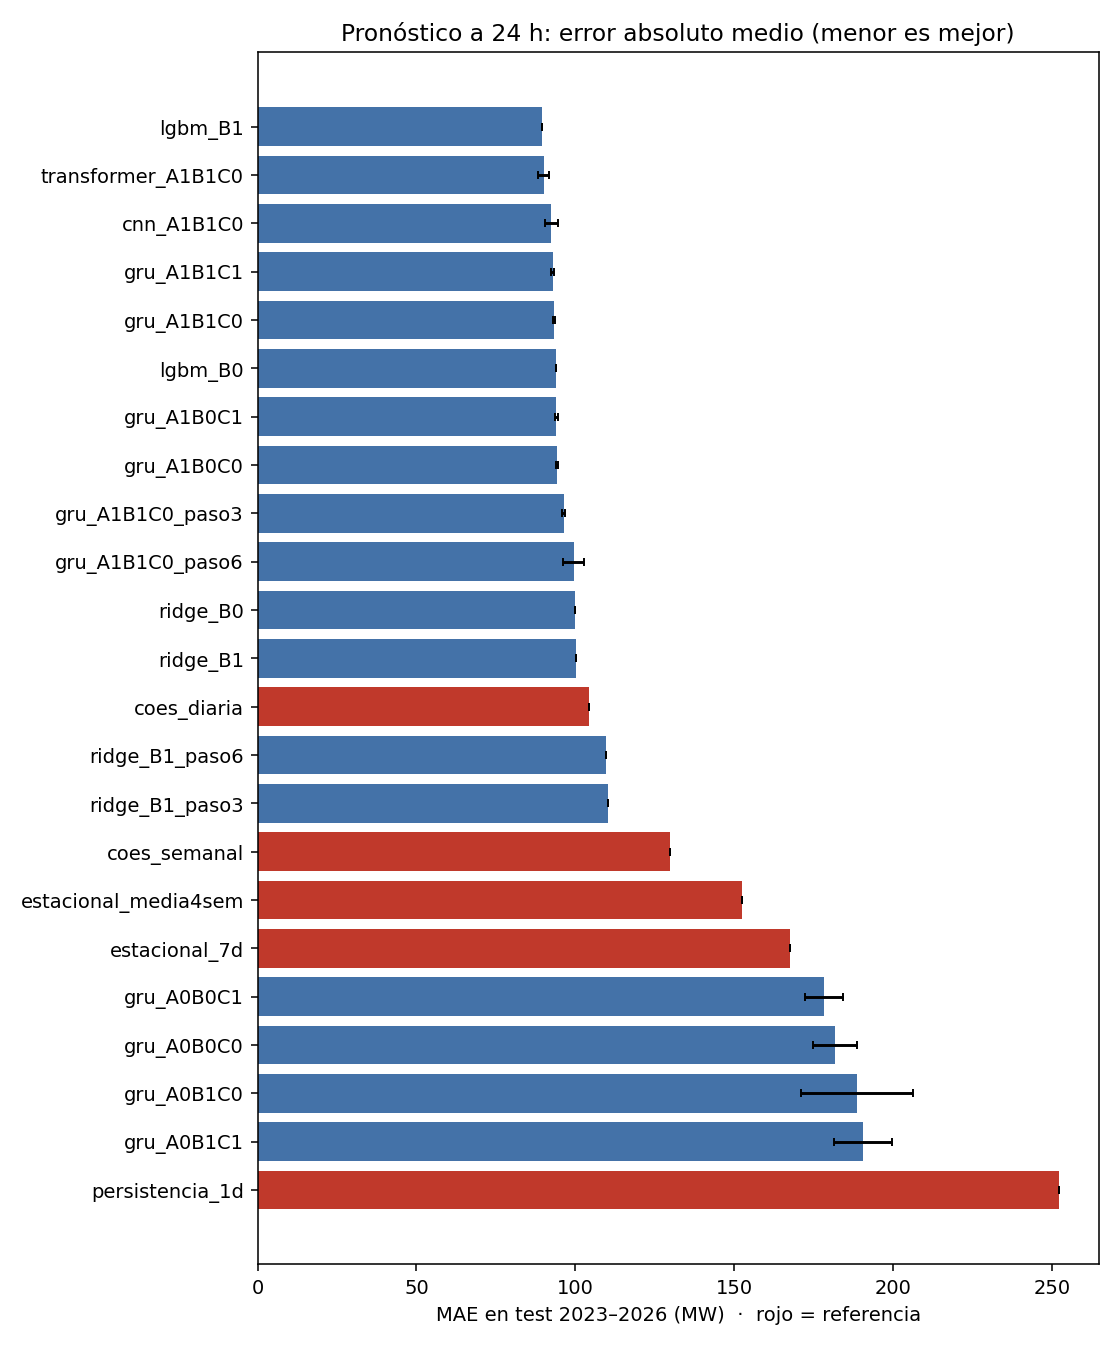

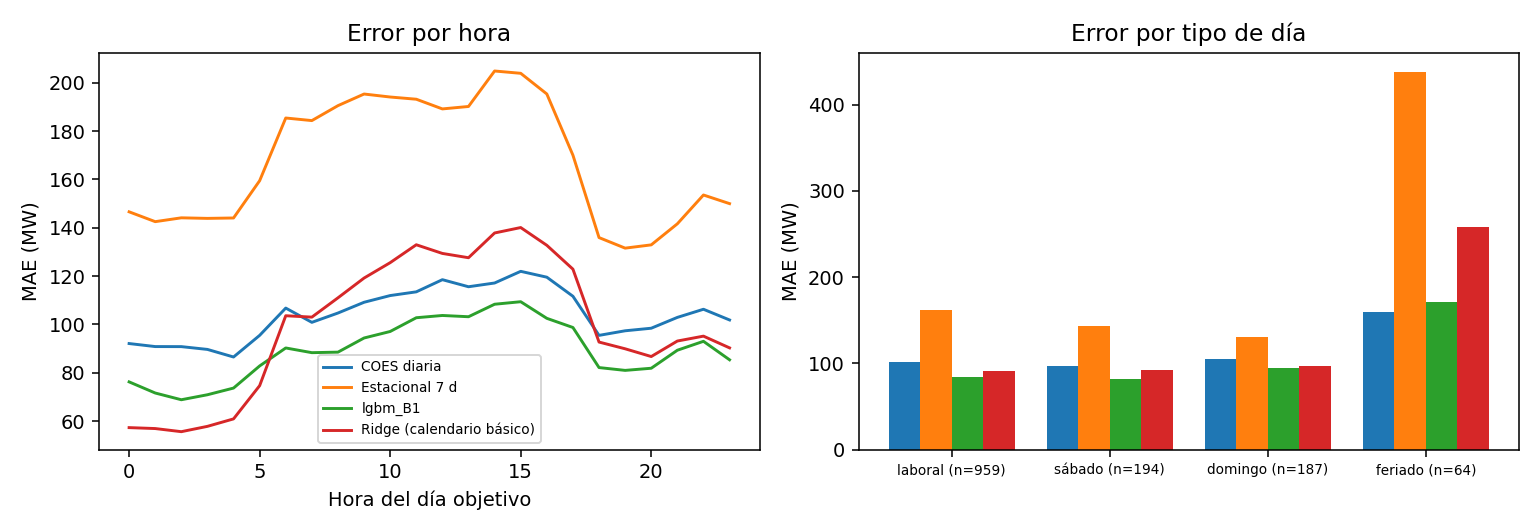

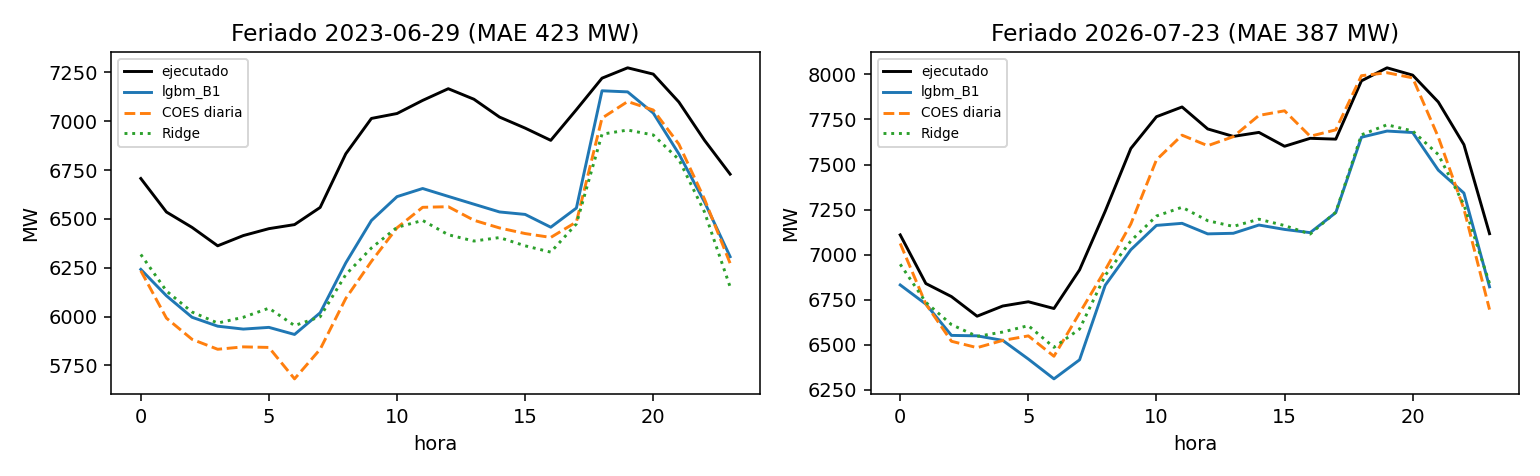

In [7]:
subprocess.run([sys.executable, "src/analizar_v2.py", SALIDA], cwd=PROYECTO, check=True)
import pandas as pd
from IPython.display import display, Image
R = PROYECTO / SALIDA
display(pd.read_csv(R / "tabla_v2.csv").round(2))
for f in ("efectos_factoriales.csv", "mezcla.csv", "comparaciones_v2.csv"):
    if (R / f).is_file():
        print(f); display(pd.read_csv(R / f))
for f in ("fig_v2_mae", "fig_v2_hora_tipodia", "fig_v2_feriados"):
    if (R / f"{f}.png").is_file():
        display(Image(str(R / f"{f}.png")))

## Lectura para el artículo
- La **referencia exigente** es Ridge con orígenes a medianoche; la programación del COES es retrospectiva (no se usa como entrada).
- Reporta media ± desv. de 3 semillas, la tabla factorial, los efectos A/B/C, la mezcla calibrada en `val_cal` y medida solo en test, y las comparaciones pareadas con IC 95 %.
- El período 2023–2026 ya se consultó en el bloque 1: etiquétalo como **evaluación retrospectiva**.